## 2 – Khi Accuracy đánh lừa

In [1]:
# -*- coding: utf-8 -*-


import pandas as pd
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("data/sinh_vien_bo_hoc.csv")
print("Kich thuoc bang:", df.shape)
print(df.head())
print()
print("So sinh vien moi lop:")
print(df["bo_hoc"].value_counts().to_string())
print(f"Ty le bo hoc: {df['bo_hoc'].mean():.3f}")
print()

X = df.drop(columns="bo_hoc")
y = df["bo_hoc"]
# stratify=y giữđúng tỷlệbỏhọc ởcảtập học lẫn tập kiểm tra
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)
print(f"Tap kiem tra: {len(y_te)} ban, {y_te.sum()} ban bo hoc")
print()

# Mô hình lười: ai cũng đoán là lớp đông nhất
luoi = DummyClassifier(strategy="most_frequent").fit(X_tr, y_tr)
du_luoi = luoi.predict(X_te)

lr = make_pipeline(StandardScaler(), LogisticRegression())
lr.fit(X_tr, y_tr)
du_lr = lr.predict(X_te)

for ten, du in [("Mo hinh luoi", du_luoi), ("Hoi quy logistic", du_lr)]:
    acc = accuracy_score(y_te, du)
    tim_ra = ((du == 1) & (y_te == 1)).sum()
    print(f"{ten:17s} accuracy {acc:.4f}, "
         f"tim ra {tim_ra} tren {y_te.sum()} ban bo hoc")


Kich thuoc bang: (1200, 5)
   diem_tb  so_buoi_vang  tin_chi_no  gio_lam_them  bo_hoc
0      8.0             3           0             0       0
1      8.9             5           1             7       0
2      3.3             3           1             4       0
3      6.4             3           0             7       0
4      7.9             3           5            23       0

So sinh vien moi lop:
bo_hoc
0    1081
1     119
Ty le bo hoc: 0.099

Tap kiem tra: 300 ban, 30 ban bo hoc

Mo hinh luoi      accuracy 0.9000, tim ra 0 tren 30 ban bo hoc
Hoi quy logistic  accuracy 0.9467, tim ra 17 tren 30 ban bo hoc


##  3 – Ma trận nhầm lẫn

In [2]:
# -*- coding: utf-8 -*-

import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("data/sinh_vien_bo_hoc.csv")
X = df.drop(columns="bo_hoc")
y = df["bo_hoc"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

lr = make_pipeline(StandardScaler(), LogisticRegression())
du = lr.fit(X_tr, y_tr).predict(X_te)
that = y_te.to_numpy()

# Tựđếm: mỗi ô là một cặp (nhãn thật, nhãn đoán)
tp = np.sum((that == 1) & (du == 1))
fp = np.sum((that == 0) & (du == 1))
fn = np.sum((that == 1) & (du == 0))
tn = np.sum((that == 0) & (du == 0))
print("Tu dem:")
print(f"TP = {tp}(doan bo hoc, dung la bo hoc)")
print(f"FP = {fp}(bao dong nham)")
print(f"FN = {fn}(bo sot)")
print(f"TN = {tn}(doan khong bo, dung la khong bo)")
print(f"Tong = {tp + fp + fn + tn}")
print()

m = confusion_matrix(that, du)
print("confusion_matrix cua scikit-learn:")
print(m)
print("Thu tu khi trai ra: TN, FP, FN, TP =", m.ravel())
print()

acc = (tp + tn) / (tp + fp + fn + tn)
print(f"Accuracy tinh tu bon o: ({tp} + {tn}) / {len(that)} = {acc:.4f}")
print(f"So ban bi bao co nguy co: TP + FP = {tp + fp}")


Tu dem:
TP = 17(doan bo hoc, dung la bo hoc)
FP = 3(bao dong nham)
FN = 13(bo sot)
TN = 267(doan khong bo, dung la khong bo)
Tong = 300

confusion_matrix cua scikit-learn:
[[267   3]
 [ 13  17]]
Thu tu khi trai ra: TN, FP, FN, TP = [267   3  13  17]

Accuracy tinh tu bon o: (17 + 267) / 300 = 0.9467
So ban bi bao co nguy co: TP + FP = 20


##  4 – Precision, Recall và F1

In [3]:
# -*- coding: utf-8 -*-

import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (classification_report, confusion_matrix,
                           f1_score, precision_score, recall_score)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("data/sinh_vien_bo_hoc.csv")
X = df.drop(columns="bo_hoc")
y = df["bo_hoc"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

lr = make_pipeline(StandardScaler(), LogisticRegression())
du = lr.fit(X_tr, y_tr).predict(X_te)
tn, fp, fn, tp = confusion_matrix(y_te, du).ravel()

p = tp / (tp + fp)
r = tp / (tp + fn)
f1 = 2 * p * r / (p + r)
print("Tinh tay tu bon o:")
print(f"Precision = {tp} / ({tp} + {fp}) = {p:.4f}")
print(f"Recall= {tp} / ({tp} + {fn}) = {r:.4f}")
print(f"F1= 2 x {p:.4f} x {r:.4f} / ({p:.4f} + {r:.4f})"
      f" = {f1:.4f}")
print()

print("Tinh bang scikit-learn:")
print(f"Precision = {precision_score(y_te, du):.4f}")
print(f"Recall= {recall_score(y_te, du):.4f}")
print(f"F1= {f1_score(y_te, du):.4f}")
print()

print("Bao cao day du:")
print(classification_report(y_te, du, digits=4,
                          target_names=["khong bo", "bo hoc"]))


Tinh tay tu bon o:
Precision = 17 / (17 + 3) = 0.8500
Recall= 17 / (17 + 13) = 0.5667
F1= 2 x 0.8500 x 0.5667 / (0.8500 + 0.5667) = 0.6800

Tinh bang scikit-learn:
Precision = 0.8500
Recall= 0.5667
F1= 0.6800

Bao cao day du:
              precision    recall  f1-score   support

    khong bo     0.9536    0.9889    0.9709       270
      bo hoc     0.8500    0.5667    0.6800        30

    accuracy                         0.9467       300
   macro avg     0.9018    0.7778    0.8255       300
weighted avg     0.9432    0.9467    0.9418       300



##  5 – Đổi ngưỡng quyết định

In [4]:
# -*- coding: utf-8 -*-

import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, precision_score, recall_score
from sklearn.model_selection import cross_val_predict, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("data/sinh_vien_bo_hoc.csv")
X = df.drop(columns="bo_hoc")
y = df["bo_hoc"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

lr = make_pipeline(StandardScaler(), LogisticRegression())
lr.fit(X_tr, y_tr)
xs = lr.predict_proba(X_te)[:, 1]# xác suất bỏhọc của từng bạn

print("Tap kiem tra, doi nguong")
print("nguongso baoTPFPFNprecisionrecallF1")
for t in [0.5, 0.4, 0.3, 0.2, 0.1]:
    du = (xs >= t).astype(int)
    tp = int(((du == 1) & (y_te == 1)).sum())
    fp = int(((du == 1) & (y_te == 0)).sum())
    fn = int(((du == 0) & (y_te == 1)).sum())
    print(f"{t:.1f}{du.sum():4d}{tp:3d} {fp:3d} {fn:3d}"
         f"{precision_score(y_te, du):.4f}"
         f"{recall_score(y_te, du):.4f}{f1_score(y_te, du):.4f}")
print()

# Chọn ngưỡng đúng cách: chỉdùng tập học, qua kiểm định chéo.
# Mỗi bạn trong tập học nhận xác suất từmột mô hình chưa từng thấy bạn ấy.
xs_hoc = cross_val_predict(lr, X_tr, y_tr, cv=5,
                         method="predict_proba")[:, 1]
cac_nguong = np.round(np.arange(0.05, 0.96, 0.05), 2)
f1_hoc = [f1_score(y_tr, (xs_hoc >= t).astype(int)) for t in cac_nguong]
t_tot = cac_nguong[int(np.argmax(f1_hoc))]
print(f"Nguong cho F1 cao nhat tren tap hoc: {t_tot}"
      f" (F1 kiem dinh cheo {max(f1_hoc):.4f})")

# Chọn xong mới dùng tập kiểm tra, và chỉmột lần
du = (xs >= t_tot).astype(int)
print(f"Tap kiem tra voi nguong {t_tot}:"
      f" precision {precision_score(y_te, du):.4f},"
      f" recall {recall_score(y_te, du):.4f},"
      f" F1 {f1_score(y_te, du):.4f}")


Tap kiem tra, doi nguong
nguongso baoTPFPFNprecisionrecallF1
0.5  20 17   3  130.85000.56670.6800
0.4  21 18   3  120.85710.60000.7059
0.3  29 21   8   90.72410.70000.7119
0.2  42 24  18   60.57140.80000.6667
0.1  61 26  35   40.42620.86670.5714

Nguong cho F1 cao nhat tren tap hoc: 0.25 (F1 kiem dinh cheo 0.6473)
Tap kiem tra voi nguong 0.25: precision 0.6571, recall 0.7667, F1 0.7077


##  6 – Đường ROC và AUC

In [5]:
# -*- coding: utf-8 -*-

import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, recall_score, roc_auc_score
from sklearn.metrics import roc_curve
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

df = pd.read_csv("data/sinh_vien_bo_hoc.csv")
X = df.drop(columns="bo_hoc")
y = df["bo_hoc"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

lr = make_pipeline(StandardScaler(), LogisticRegression())
xs = lr.fit(X_tr, y_tr).predict_proba(X_te)[:, 1]

# Mỗi ngưỡng cho một điểm của đường ROC
fpr, tpr, nguong = roc_curve(y_te, xs)
print("Duong ROC co", len(fpr), "diem. Vai diem dau:")
print("bao dong nhamrecall")
for a, b in list(zip(fpr, tpr))[:6]:
    print(f"{a:.4f}{b:.4f}")
print(f"AUC cua logistic = {roc_auc_score(y_te, xs):.4f}")
print()

# So các mô hình đã học, cùng tập học, cùng tập kiểm tra
mo_hinh = {
    "Logistic": lr,
    "Naive Bayes": GaussianNB(),
    "KNN, k = 15": make_pipeline(StandardScaler(),
                              KNeighborsClassifier(15)),
    "Cay sau 4": DecisionTreeClassifier(max_depth=4, random_state=0),
    "Rung 200 cay": RandomForestClassifier(200, random_state=0),
    "SVM RBF": make_pipeline(StandardScaler(),
                           SVC(probability=True, random_state=0)),
}
print("Mo hinhAUCrecallF1(nguong 0.5)")
for ten, mh in mo_hinh.items():
    mh.fit(X_tr, y_tr)
    p = mh.predict_proba(X_te)[:, 1]
    du = (p >= 0.5).astype(int)
    print(f"{ten:14s} {roc_auc_score(y_te, p):.4f}"
         f"{recall_score(y_te, du):.4f}{f1_score(y_te, du):.4f}")


Duong ROC co 28 diem. Vai diem dau:
bao dong nhamrecall
0.00000.0000
0.00000.0333
0.00000.4000
0.00740.4000
0.00740.5333
0.01110.5333
AUC cua logistic = 0.9449

Mo hinhAUCrecallF1(nguong 0.5)
Logistic       0.94490.56670.6800
Naive Bayes    0.93360.36670.5116
KNN, k = 15    0.92740.23330.3684
Cay sau 4      0.88030.46670.5957
Rung 200 cay   0.92490.56670.6538
SVM RBF        0.89960.50000.6250


##  7 – Kiểm định chéo và cân bằng lớp

In [6]:
# -*- coding: utf-8 -*-

import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, precision_score, recall_score
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("data/sinh_vien_bo_hoc.csv")
X = df.drop(columns="bo_hoc")
y = df["bo_hoc"]

# Chia không phân tầng: sốbạn bỏhọc trong tập kiểm tra dao động
print("Khong stratify, so ban bo hoc trong tap kiem tra:")
dem = []
for rs in range(10):
    _, _, _, y_te_thu = train_test_split(X, y, test_size=0.25,
                                      random_state=rs)
    dem.append(int(y_te_thu.sum()))
print(" ", dem)
print()

X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

lr = make_pipeline(StandardScaler(), LogisticRegression())
print("Kiem dinh cheo 5 phan tren tap hoc:")
for tm in ["accuracy", "precision", "recall", "f1"]:
    d = cross_val_score(lr, X_tr, y_tr, cv=5, scoring=tm)
    print(f"{tm:10s} {d.mean():.4f}")
print()

# Cân bằng lớp: phạt nặng hơn khi đoán sai lớp hiếm
cb = make_pipeline(StandardScaler(),
                 LogisticRegression(class_weight="balanced"))
print("Tap kiem traprecisionrecallF1")
for ten, mh in [("Binh thuong", lr), ("Can bang lop", cb)]:
    du = mh.fit(X_tr, y_tr).predict(X_te)
    print(f"{ten:12s}{precision_score(y_te, du):.4f}"
         f"{recall_score(y_te, du):.4f}{f1_score(y_te, du):.4f}")


Khong stratify, so ban bo hoc trong tap kiem tra:
  [22, 26, 35, 29, 32, 27, 28, 20, 27, 23]

Kiem dinh cheo 5 phan tren tap hoc:
accuracy   0.9289
precision  0.7044
recall     0.4810
f1         0.5652

Tap kiem traprecisionrecallF1
Binh thuong 0.85000.56670.6800
Can bang lop0.44830.86670.5909


## Bài tập

### Bài tập 1 – Tự viết hàm đánh giá

In [7]:
import numpy as np
import pandas as pd
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

def danh_gia(y_that, y_doan):
    y_that, y_doan = np.asarray(y_that), np.asarray(y_doan)
    tp = np.sum((y_that == 1) & (y_doan == 1))
    fp = np.sum((y_that == 0) & (y_doan == 1))
    fn = np.sum((y_that == 1) & (y_doan == 0))
    tn = np.sum((y_that == 0) & (y_doan == 0))
    accuracy = (tp + tn) / len(y_that)
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    return accuracy, precision, recall, f1

df = pd.read_csv('data/sinh_vien_bo_hoc.csv')
X, y = df.drop(columns='bo_hoc'), df['bo_hoc']
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=17, stratify=y)
mo_hinh = {
    'Logistic Regression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    'DummyClassifier': DummyClassifier(strategy='most_frequent')
}
for ten, model in mo_hinh.items():
    du_doan = model.fit(X_tr, y_tr).predict(X_te)
    tu_tinh = danh_gia(y_te, du_doan)
    thu_vien = (accuracy_score(y_te, du_doan), precision_score(y_te, du_doan, zero_division=0),
                recall_score(y_te, du_doan, zero_division=0), f1_score(y_te, du_doan, zero_division=0))
    print(ten)
    print('  Tự tính: ', np.round(tu_tinh, 4))
    print('  Thư viện:', np.round(thu_vien, 4))
    assert np.allclose(tu_tinh, thu_vien)


Logistic Regression
  Tự tính:  [0.9467 0.85   0.5667 0.68  ]
  Thư viện: [0.9467 0.85   0.5667 0.68  ]
DummyClassifier
  Tự tính:  [0.9 0.  0.  0. ]
  Thư viện: [0.9 0.  0.  0. ]


**Nhận xét**

- Mô hình lười luôn đoán lớp 0 nên không có dự đoán dương tính. Khi mẫu số bằng 0, em trả Precision bằng 0 để chương trình không bị lỗi.
- Các kết quả tự tính khớp với Scikit-learn.

### Bài tập 2 – Chữ số viết tay

In [8]:
import numpy as np
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import classification_report

X, y = load_digits(return_X_y=True)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=17, stratify=y)
svm = make_pipeline(StandardScaler(), SVC(kernel='rbf', C=10, gamma='scale'))
svm.fit(X_tr, y_tr)
bao_cao = classification_report(y_te, svm.predict(X_te), digits=4, output_dict=True)
print(classification_report(y_te, svm.predict(X_te), digits=4))
nhan = [str(i) for i in range(10)]
recall_thap = min(nhan, key=lambda n: bao_cao[n]['recall'])
precision_thap = min(nhan, key=lambda n: bao_cao[n]['precision'])
print('Chữ số Recall thấp nhất:', recall_thap, bao_cao[recall_thap]['recall'])
print('Chữ số Precision thấp nhất:', precision_thap, bao_cao[precision_thap]['precision'])
print('Macro avg F1:', round(bao_cao['macro avg']['f1-score'], 4))
print('Weighted avg F1:', round(bao_cao['weighted avg']['f1-score'], 4))


              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000        45
           1     1.0000    1.0000    1.0000        46
           2     1.0000    0.9773    0.9885        44
           3     0.9778    0.9565    0.9670        46
           4     0.9375    1.0000    0.9677        45
           5     1.0000    1.0000    1.0000        46
           6     0.9783    1.0000    0.9890        45
           7     0.9773    0.9556    0.9663        45
           8     0.9767    0.9767    0.9767        43
           9     0.9545    0.9333    0.9438        45

    accuracy                         0.9800       450
   macro avg     0.9802    0.9799    0.9799       450
weighted avg     0.9803    0.9800    0.9800       450

Chữ số Recall thấp nhất: 9 0.9333333333333333
Chữ số Precision thấp nhất: 4 0.9375
Macro avg F1: 0.9799
Weighted avg F1: 0.98


**Nhận xét**

- Macro avg và weighted avg gần nhau vì số ảnh của các chữ số khá đồng đều.
- Chữ số có Precision và Recall thấp nhất được in từ kết quả chạy, không đoán trước.

### Bài tập 3 – Chọn ngưỡng với Recall tối thiểu 80%

In [9]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, cross_val_predict, StratifiedKFold
from sklearn.metrics import precision_score, recall_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

df = pd.read_csv('data/sinh_vien_bo_hoc.csv')
X, y = df.drop(columns='bo_hoc'), df['bo_hoc']
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=17, stratify=y)
model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
p_cv = cross_val_predict(model, X_tr, y_tr, cv=cv, method='predict_proba')[:, 1]
# Chọn ngưỡng lớn nhất trên tập học, tuyệt đối không nhìn tập kiểm tra
nguong = np.unique(np.r_[0.0, p_cv, 1.0])
hop_le = [t for t in nguong if recall_score(y_tr, p_cv >= t, zero_division=0) >= 0.8]
nguong_tot = max(hop_le)
print('Ngưỡng chọn từ tập học:', round(float(nguong_tot), 5))
print('Recall kiểm định chéo:', round(recall_score(y_tr, p_cv >= nguong_tot), 4))
model.fit(X_tr, y_tr)
p_test = model.predict_proba(X_te)[:, 1]
du_doan = (p_test >= nguong_tot).astype(int)
print('Recall tập kiểm tra:', round(recall_score(y_te, du_doan), 4))
print('Precision tập kiểm tra:', round(precision_score(y_te, du_doan, zero_division=0), 4))
print('Số sinh viên được cảnh báo:', int(du_doan.sum()))


Ngưỡng chọn từ tập học: 0.18103
Recall kiểm định chéo: 0.809
Recall tập kiểm tra: 0.8
Precision tập kiểm tra: 0.5106
Số sinh viên được cảnh báo: 47


**Nhận xét**

- Em chỉ dùng xác suất kiểm định chéo trên tập học để chọn ngưỡng.
- Recall trên tập kiểm tra có thể khác 80% vì đây là dữ liệu chưa được dùng để chọn ngưỡng.

### Bài tập 4 – Tự vẽ đường ROC

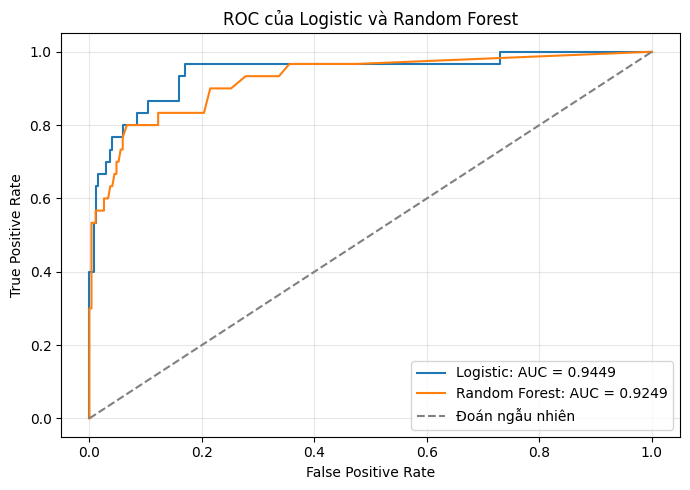

Mô hình có AUC cao hơn: Logistic
Hai đường có đổi thứ tự theo FPR: True
Đã lưu roc.png


In [10]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

df = pd.read_csv('data/sinh_vien_bo_hoc.csv')
X, y = df.drop(columns='bo_hoc'), df['bo_hoc']
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=17, stratify=y)
models = {
    'Logistic': make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    'Random Forest': RandomForestClassifier(n_estimators=200, random_state=0)
}
duong = {}
plt.figure(figsize=(7, 5))
for ten, model in models.items():
    p = model.fit(X_tr, y_tr).predict_proba(X_te)[:, 1]
    fpr, tpr, _ = roc_curve(y_te, p)
    auc = roc_auc_score(y_te, p)
    plt.plot(fpr, tpr, label=f'{ten}: AUC = {auc:.4f}')
    duong[ten] = (fpr, tpr, auc)
plt.plot([0, 1], [0, 1], '--', color='gray', label='Đoán ngẫu nhiên')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC của Logistic và Random Forest')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('roc.png', dpi=150)
plt.show()
print('Mô hình có AUC cao hơn:', max(duong, key=lambda k: duong[k][2]))
# Kiểm tra hai đường trên cùng dải FPR bằng nội suy
import numpy as np
luoi = np.linspace(0, 1, 1001)
chenh = np.interp(luoi, *duong['Logistic'][:2]) - np.interp(luoi, *duong['Random Forest'][:2])
print('Hai đường có đổi thứ tự theo FPR:', bool(np.any(chenh > 1e-5) and np.any(chenh < -1e-5)))
print('Đã lưu roc.png')


**Nhận xét**

- Đường ROC càng sát góc trên bên trái thì càng tốt.
- Em so sánh AUC và kiểm tra hai đường có đổi thứ tự theo FPR hay không.

### Bài tập 5 – Cân bằng lớp cho Random Forest và SVM

In [11]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import precision_score, recall_score, f1_score

df = pd.read_csv('data/sinh_vien_bo_hoc.csv')
X, y = df.drop(columns='bo_hoc'), df['bo_hoc']
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=17, stratify=y)
ket_qua = {}
for ten, tao_mo_hinh in [
    ('Random Forest', lambda w: RandomForestClassifier(n_estimators=200, class_weight=w, random_state=0)),
    ('SVM', lambda w: make_pipeline(StandardScaler(), SVC(class_weight=w, random_state=0)))
]:
    ket_qua[ten] = {}
    for w in [None, 'balanced']:
        du = tao_mo_hinh(w).fit(X_tr, y_tr).predict(X_te)
        diem = (precision_score(y_te, du, zero_division=0),
                recall_score(y_te, du, zero_division=0),
                f1_score(y_te, du, zero_division=0))
        ket_qua[ten][str(w)] = diem
        print(ten, '| Cân bằng:', w, '| Precision / Recall / F1:', [round(z, 4) for z in diem])
for ten in ket_qua:
    cu = ket_qua[ten]['None']
    moi = ket_qua[ten]['balanced']
    print(ten, 'mức thay đổi F1:', round(moi[2] - cu[2], 4))


Random Forest | Cân bằng: None | Precision / Recall / F1: [0.7727, 0.5667, 0.6538]
Random Forest | Cân bằng: balanced | Precision / Recall / F1: [0.75, 0.4, 0.5217]
SVM | Cân bằng: None | Precision / Recall / F1: [0.8824, 0.5, 0.6383]
SVM | Cân bằng: balanced | Precision / Recall / F1: [0.4464, 0.8333, 0.5814]
Random Forest mức thay đổi F1: -0.1321
SVM mức thay đổi F1: -0.0569


**Nhận xét**

- Class_weight điều chỉnh mức phạt cho lớp ít mẫu, không đảm bảo mọi chỉ số đều tăng.
- Em dựa vào bảng kết quả và độ thay đổi F1 để nhận xét mô hình nào bị ảnh hưởng nhiều.

### Bài tập 6 – MAE và RMSE khi có một dự đoán sai lớn

In [12]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

df = pd.read_csv('data/gia_nha.csv')
X, y = df[['dien_tich']], df['gia']
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=17)
model = LinearRegression().fit(X_tr, y_tr)
p = model.predict(X_te)
p_sai = p.copy()
p_sai[0] += 5  # Chỉ làm sai dự đoán của một căn, đơn vị tỷ đồng
for ten, du in [('Ban đầu', p), ('Một dự đoán cộng thêm 5 tỷ', p_sai)]:
    mae = mean_absolute_error(y_te, du)
    rmse = np.sqrt(mean_squared_error(y_te, du))
    r2 = r2_score(y_te, du)
    print(ten, '| MAE:', round(mae, 4), '| RMSE:', round(rmse, 4), '| R2:', round(r2, 4))


Ban đầu | MAE: 0.3123 | RMSE: 0.3983 | R2: 0.9475
Một dự đoán cộng thêm 5 tỷ | MAE: 0.6456 | RMSE: 1.4566 | R2: 0.2983


**Nhận xét**

- RMSE dùng bình phương sai số nên nhạy hơn MAE khi có một dự đoán bị lệch lớn.
- R² cũng có thể giảm mạnh vì tổng bình phương sai số tăng.